# League of Legends: predicting `blueWins` from the first 10 minutes

**Group 44:** Anton Andersson, Liam Jörgensen, Rasmus Rolin

- **Dataset:** [League of Legends Diamond Ranked Games (10 min)](https://www.kaggle.com/datasets/bobbyscience/league-of-legends-diamond-ranked-games-10-min), Kaggle
- **Problem type:** binary classification: `blueWins` = 1 if the blue team won, 0 if it lost
- **Algorithm 1:** Logistic Regression, implemented from scratch with NumPy
- **Algorithm 2:** Random Forest (scikit-learn)

## 1. Import libraries

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

SEED = 16  # fixed random seed so every run gives the same result. Controls which gmeas end up in train/test split and randomness inside Random Forest.
DATA_PATH = Path("data") / "high_diamond_ranked_10min.csv"

# every plot is also saved here so it can be used in the report
FIG_DIR = Path("figures")  
FIG_DIR.mkdir(exist_ok=True) # Make it not crash if folder exists

# Colors for the plots: blue team = blue, red team = red
BLUE, RED, GREY = "#2a78d6", "#d63a2a", "#52514e"

#The plot style for the entire notebook
# saved pngs get higher resolution (150) than the ones in the notebook (100).
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 150, "savefig.bbox": "tight",
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e4e3df", "axes.axisbelow": True, "legend.frameon": False})
#Raises the limite set by pandas to 50 instead of the default 20 columns shown
pd.set_option("display.max_columns", 50)

## 2. Load the dataset
Each row is one game and the columns are the games values at exactly minute 10.

In [2]:
#Loads csv into pandas and checkit was loaded
df = pd.read_csv(DATA_PATH)
print(f"Loaded {df.shape[0]} games with {df.shape[1]} columns")
#Show first 5 games
df.head()

Loaded 9879 games with 40 columns


,gameId,blueWins,blueWardsPlaced,blueWardsDestroyed,blueFirstBlood,blueKills,blueDeaths,blueAssists,blueEliteMonsters,blueDragons,blueHeralds,blueTowersDestroyed,blueTotalGold,blueAvgLevel,blueTotalExperience,blueTotalMinionsKilled,blueTotalJungleMinionsKilled,blueGoldDiff,blueExperienceDiff,blueCSPerMin,blueGoldPerMin,redWardsPlaced,redWardsDestroyed,redFirstBlood,redKills,redDeaths,redAssists,redEliteMonsters,redDragons,redHeralds,redTowersDestroyed,redTotalGold,redAvgLevel,redTotalExperience,redTotalMinionsKilled,redTotalJungleMinionsKilled,redGoldDiff,redExperienceDiff,redCSPerMin,redGoldPerMin
0,4519157822,0,28,2,1,9,6,11,0,0,0,0,17210,6.6,17039,195,36,643,-8,19.5,1721.0,15,6,0,6,9,8,0,0,0,0,16567,6.8,17047,197,55,-643,8,19.7,1656.7
1,4523371949,0,12,1,0,5,5,5,0,0,0,0,14712,6.6,16265,174,43,-2908,-1173,17.4,1471.2,12,1,1,5,5,2,2,1,1,1,17620,6.8,17438,240,52,2908,1173,24.0,1762.0
2,4521474530,0,15,0,0,7,11,4,1,1,0,0,16113,6.4,16221,186,46,-1172,-1033,18.6,1611.3,15,3,1,11,7,14,0,0,0,0,17285,6.8,17254,203,28,1172,1033,20.3,1728.5
3,4524384067,0,43,1,0,4,5,5,1,0,1,0,15157,7.0,17954,201,55,-1321,-7,20.1,1515.7,15,2,1,5,4,10,0,0,0,0,16478,7.0,17961,235,47,1321,7,23.5,1647.8
4,4436033771,0,75,4,0,6,6,6,0,0,0,0,16400,7.0,18543,210,57,-1004,230,21.0,1640.0,17,2,1,6,6,7,1,1,0,0,17404,7.0,18313,225,67,1004,-230,22.5,1740.4


## 3. Explore the data
### 3.1 Size, data types, missing values and duplicates

In [3]:
#calculate missing and duplicate values 
n_missing = int(df.isna().sum().sum())
n_duplicates = int(df.duplicated().sum())

print(f"Rows: {df.shape[0]}, columns: {df.shape[1]}")

print(f"Data types: {df.dtypes.value_counts().to_dict()}")
print(f"Missing values: {n_missing}")
print(f"Duplicate rows: {n_duplicates}")

Rows: 9879, columns: 40
Data types: {dtype('int64'): 34, dtype('float64'): 6}
Missing values: 0
Duplicate rows: 0


Statistics for every column (mean, standard deviation, min, max, etc)

In [4]:
def short_number(x):
    #Round to 4 decimals and stop trailing 0s
    return f"{x:.4f}".rstrip("0").rstrip(".")


df.describe().T.style.format(short_number)

,count,mean,std,min,25%,50%,75%,max
gameId,9879,4500084044.8455,27573278.4909,4295358071,4483301169,4510920346,4521733208.5,4527990640
blueWins,9879,0.499,0.5,0,0,0,1,1
blueWardsPlaced,9879,22.2883,18.0192,5,14,16,20,250
blueWardsDestroyed,9879,2.8249,2.175,0,1,3,4,27
blueFirstBlood,9879,0.5048,0.5,0,0,1,1,1
blueKills,9879,6.1839,3.011,0,4,6,8,22
blueDeaths,9879,6.1377,2.9338,0,4,6,8,22
blueAssists,9879,6.6451,4.0645,0,4,6,9,29
blueEliteMonsters,9879,0.55,0.6255,0,0,0,1,2
blueDragons,9879,0.362,0.4806,0,0,0,1,1


### 3.2 Class balance
If one class were much bigger than the other, accuracy could be misleading. Here the classes are almost equal.

Blue lost: 4949, blue won: 4930


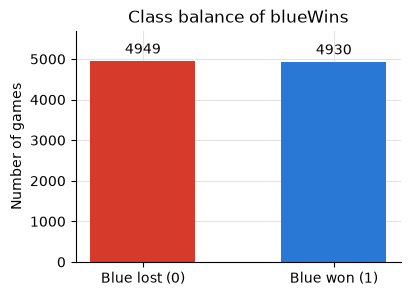

In [5]:
#count how many games blue lost (0) and wond (1)
class_counts = df["blueWins"].value_counts().sort_index()
print(f"Blue lost: {class_counts[0]}, blue won: {class_counts[1]}")

#create the figure
fig, ax = plt.subplots(figsize=(4.2, 3))
bars = ax.bar(["Blue lost (0)", "Blue won (1)"], class_counts.values, color=[RED, BLUE], width=0.55)
ax.bar_label(bars, padding=3)
ax.set_ylabel("Number of games")
ax.set_title("Class balance of blueWins")
ax.set_ylim(0, class_counts.max() * 1.15)
fig.savefig(FIG_DIR / "01_class_balance.png")
plt.show()

### 3.3 Redundant columns

In [6]:
#each entry is something we think might be true and we just test it on every single game
#Essentially these entries are redundancies we believe to exist and we just test them
redundancy_checks = {
    "redFirstBlood = 1 - blueFirstBlood": (df.redFirstBlood == 1 - df.blueFirstBlood).all(),
    "redKills = blueDeaths": (df.redKills == df.blueDeaths).all(),
    "redDeaths = blueKills": (df.redDeaths == df.blueKills).all(),
    "redGoldDiff = -blueGoldDiff": (df.redGoldDiff == -df.blueGoldDiff).all(),
    "redExperienceDiff = -blueExperienceDiff": (df.redExperienceDiff == -df.blueExperienceDiff).all(),
    "blueGoldDiff = blueTotalGold - redTotalGold": (df.blueGoldDiff == df.blueTotalGold - df.redTotalGold).all(),
    "blueExperienceDiff = blueTotalExperience - redTotalExperience":
        (df.blueExperienceDiff == df.blueTotalExperience - df.redTotalExperience).all(),
    "blueGoldPerMin = blueTotalGold / 10": np.allclose(df.blueGoldPerMin, df.blueTotalGold / 10),
    "blueCSPerMin = blueTotalMinionsKilled / 10": np.allclose(df.blueCSPerMin, df.blueTotalMinionsKilled / 10),
    "blueEliteMonsters = blueDragons + blueHeralds": (df.blueEliteMonsters == df.blueDragons + df.blueHeralds).all(),
}
#Print for everry rule
for rule, holds in redundancy_checks.items():
    print(f"{str(holds):<6} {rule}")

True   redFirstBlood = 1 - blueFirstBlood
True   redKills = blueDeaths
True   redDeaths = blueKills
True   redGoldDiff = -blueGoldDiff
True   redExperienceDiff = -blueExperienceDiff
True   blueGoldDiff = blueTotalGold - redTotalGold
True   blueExperienceDiff = blueTotalExperience - redTotalExperience
True   blueGoldPerMin = blueTotalGold / 10
True   blueCSPerMin = blueTotalMinionsKilled / 10
True   blueEliteMonsters = blueDragons + blueHeralds


### 3.4 Unusual values

In [7]:
# Some games had insane ward outliars, count them
n_ward_outliers = int(((df.blueWardsPlaced > 100) | (df.redWardsPlaced > 100)).sum())

print(f"Median wards placed: {df.blueWardsPlaced.median():.0f}")
print(f"Max wards placed: {max(df.blueWardsPlaced.max(), df.redWardsPlaced.max())}")
print(f"Games where a team placed more than 100 wards: {n_ward_outliers}")

Median wards placed: 16
Max wards placed: 276
Games where a team placed more than 100 wards: 216


### 3.5 Which stats are related to winning?
Correlation is a number from −1 to 1. Close to 1: when this stat is high, blue usually wins. Close to −1: the opposite. Around 0: no straight-line relationship.

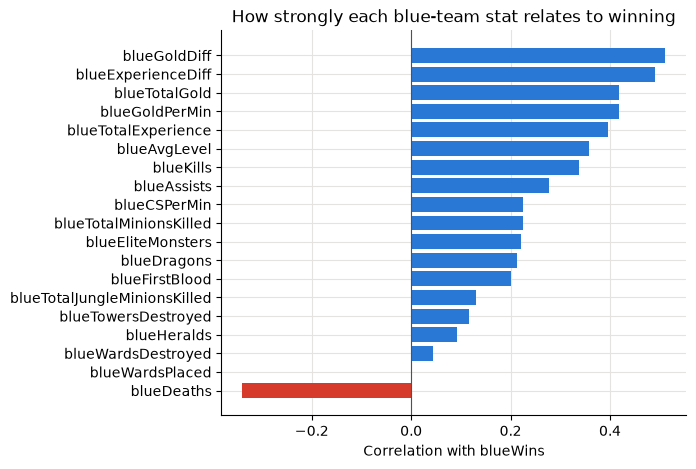

In [8]:
# correlation of every stat with blueWins (excluding id and blueWins)
correlation = df.drop(columns=["gameId"]).corr()["blueWins"].drop("blueWins")
blue_corr = correlation[[c for c in correlation.index if c.startswith("blue")]].sort_values() # only care about blue stats since red are pretty much mirrored

fig, ax = plt.subplots(figsize=(6, 5))
ax.barh(blue_corr.index, blue_corr.values, color=[BLUE if v > 0 else RED for v in blue_corr.values])
ax.axvline(0, color=GREY, linewidth=0.8)
ax.set_xlabel("Correlation with blueWins")
ax.set_title("How strongly each blue-team stat relates to winning")
fig.savefig(FIG_DIR / "02_correlation_with_target.png")
plt.show()

The gold difference is the strongest single stat

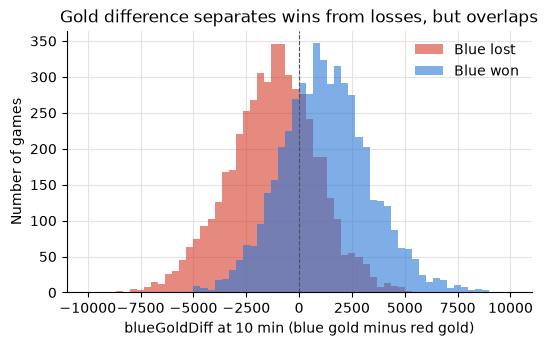

In [9]:
fig, ax = plt.subplots(figsize=(6, 3.4))
bins = np.linspace(-10000, 10000, 61)
ax.hist(df.loc[df.blueWins == 0, "blueGoldDiff"], bins=bins, alpha=0.6, color=RED, label="Blue lost")
ax.hist(df.loc[df.blueWins == 1, "blueGoldDiff"], bins=bins, alpha=0.6, color=BLUE, label="Blue won")
ax.axvline(0, color=GREY, linewidth=0.8, linestyle="--")
ax.set_xlabel("blueGoldDiff at 10 min (blue gold minus red gold)")
ax.set_ylabel("Number of games")
ax.set_title("Gold difference separates wins from losses, but overlaps")
ax.legend()
fig.savefig(FIG_DIR / "03_gold_diff_hist.png")
plt.show()

Win rate for groups of games with a similar gold difference, the shape looks like the sigmoid function on logistic regression.

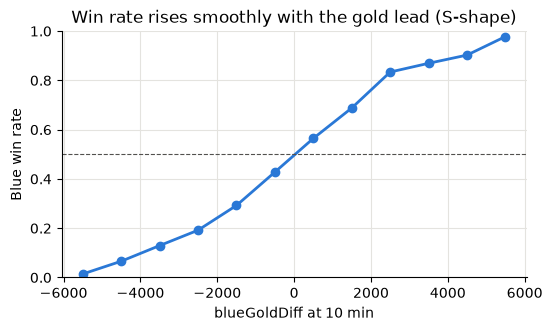

In [10]:
# Group games in groups of 1k gold, the games with bigger are left out for this plot
gold_groups = pd.cut(df.blueGoldDiff, bins=np.arange(-6000, 6001, 1000))
win_rate = df.groupby(gold_groups, observed=True)["blueWins"].mean()

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot([g.mid for g in win_rate.index], win_rate.values, color=BLUE, linewidth=2, marker="o")
ax.axhline(0.5, color=GREY, linewidth=0.8, linestyle="--")
ax.set_xlabel("blueGoldDiff at 10 min")
ax.set_ylabel("Blue win rate")
ax.set_ylim(0, 1)
ax.set_title("Win rate rises smoothly with the gold lead (S-shape)")
fig.savefig(FIG_DIR / "04_winrate_by_gold.png")
plt.show()

## 4. Preprocess the data
- Removing `gameId` since its only an ID number
- The other columns removed can just be calculated from other columns that are kept, so they're not needed (see 3.3)
- The ward outliers are real games, so we keep them. Scaling (step 6) evens out the features varying magnitude in values

In [11]:
# drops the columns that were redundant / not needed 
DROP_COLUMNS = {
    "gameId": "ID number, says nothing about the game",
    "redFirstBlood": "= 1 - blueFirstBlood",
    "redKills": "= blueDeaths",
    "redDeaths": "= blueKills",
    "redGoldDiff": "= -blueGoldDiff",
    "redExperienceDiff": "= -blueExperienceDiff",
    "blueGoldPerMin": "= blueTotalGold / 10",
    "redGoldPerMin": "= redTotalGold / 10",
    "blueCSPerMin": "= blueTotalMinionsKilled / 10",
    "redCSPerMin": "= redTotalMinionsKilled / 10",
    "blueEliteMonsters": "= blueDragons + blueHeralds",
    "redEliteMonsters": "= redDragons + redHeralds",
    "blueTotalGold": "replaced by blueGoldDiff (blue gold - red gold)",
    "redTotalGold": "replaced by blueGoldDiff",
    "blueTotalExperience": "replaced by blueExperienceDiff (blue XP - red XP)",
    "redTotalExperience": "replaced by blueExperienceDiff",
}
df_clean = df.drop(columns=list(DROP_COLUMNS))
print(f"Removed {len(DROP_COLUMNS)} columns, {df_clean.shape[1] - 1} features left")

Removed 16 columns, 23 features left


## 5. Define features and target

In [12]:
X = df_clean.drop(columns=["blueWins"])  # the inputs (features)
y = df_clean["blueWins"]                 # what we want to predict (target)

#Save the column names because numpy doesnt keep it after scaling :))))
feature_names = list(X.columns)
print(feature_names)

['blueWardsPlaced', 'blueWardsDestroyed', 'blueFirstBlood', 'blueKills', 'blueDeaths', 'blueAssists', 'blueDragons', 'blueHeralds', 'blueTowersDestroyed', 'blueAvgLevel', 'blueTotalMinionsKilled', 'blueTotalJungleMinionsKilled', 'blueGoldDiff', 'blueExperienceDiff', 'redWardsPlaced', 'redWardsDestroyed', 'redAssists', 'redDragons', 'redHeralds', 'redTowersDestroyed', 'redAvgLevel', 'redTotalMinionsKilled', 'redTotalJungleMinionsKilled']


## 6. Split into training and test sets, then scale the features
- **80 %** of the games are used for training, **20 %** are kept aside for the final test. `stratify=y` keeps the same share of wins and losses in both
- **Standardisation:** $z = \dfrac{x - \text{mean}}{\text{std}}$, so every feature gets mean 0 and standard deviation 1.

In [ ]:
#80% for training 20% testing. Stratifying keeps the same share of wins / losses in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)

#Scales all features to a mean of 0 and std 1 so that large values like gold diff and smaller values like wards placed are on the same scale.
train_mean = X_train.mean()
train_std = X_train.std()
X_train_scaled = ((X_train - train_mean) / train_std).to_numpy()
X_test_scaled = ((X_test - train_mean) / train_std).to_numpy()

#setup numpy arrays for logistic regression
y_train = y_train.to_numpy()
y_test = y_test.to_numpy()
print(f"Training games: {len(y_train)}, test games: {len(y_test)}")

Training games: 7903, test games: 1976


## 7. Algorithm 1: Logistic Regression
1. **Score:** $z = w_1x_1 + w_2x_2 + \dots + w_{23}x_{23} + b$
2. **Probability** that blue wins (sigmoid): $p = \sigma(z) = \dfrac{1}{1 + e^{-z}}$. Predict 1 if $p \ge 0.5$.
3. **Loss** (binary cross-entropy): $\text{Loss} = -\dfrac{1}{m}\sum \big[y\log(p) + (1-y)\log(1-p)\big]$
4. **Gradient descent:** $w \leftarrow w - \alpha \cdot \dfrac{1}{m}X^T(p - y)$ and $b \leftarrow b - \alpha \cdot \dfrac{1}{m}\sum(p - y)$, where $\alpha$ is the learning rate.

In [ ]:
class LogisticRegression:
    """Logistic regression trained with gradient descent.

    Prediction: p = sigmoid(X @ w + b)   = probability that blue wins
    Loss:       binary cross-entropy (log loss)
    """

    def __init__(self, learning_rate=0.1, n_iterations=1000):
        self.learning_rate = learning_rate #the size of each step
        self.n_iterations = n_iterations #how many steps to take

    def sigmoid(self, z):
        z = np.clip(z, -500, 500)  # avoid overflow in np.exp for huge values
        return 1 / (1 + np.exp(-z))

    def fit(self, X, y):
        n_samples, n_features = X.shape
        #All weights start at zero which means ever game starts at p=0.5
        self.w = np.zeros(n_features)  # one weight per feature, start at 0
        self.b = 0.0 # bias stats at 0 and ends up pretty much zero due to the class balance
        self.loss_history = [] #Loss after every step used for plots latre


        #every step uses all the training games, one round of the loop is one step of the gradient descent
        for _ in range(self.n_iterations):
            #1 Score and probability for every trianing game (X @ w is matrix multiplication so each feature is multiplied by each weight)
            p = self.sigmoid(X @ self.w + self.b)

            #2 Loss: how wrong the model is essentailly. (lower is better)
            eps = 1e-12  # avoids log(0)
            # p = 0.9 for a game blue won gives a loss of 0.11 but p = 0.1 gives 2.3 in order to punish confident confident wrong answers the most
            #used to follow training and pick learning rate
            loss = -np.mean(y * np.log(p + eps) + (1 - y) * np.log(1 - p + eps))
            self.loss_history.append(loss)

            #3 error: how far off each prediction is and in which direction
            # blue won (y=1) but model said 0.3 means and error of -0.7 (guessed too low)
            error = p - y
            grad_w = (X.T @ error) / n_samples
            grad_b = np.mean(error)

            #4 The gradient points in the direction that makes the loss bigger so step the other way
            self.w -= self.learning_rate * grad_w
            self.b -= self.learning_rate * grad_b
        return self

    def predict_proba(self, X):
        #same calculation as step 1 but with finished weights used on the test set
        return self.sigmoid(X @ self.w + self.b)

    def predict(self, X, threshold=0.5):
        #this turns the probability into an answer 1 = blueWins if p is at least 0.5, otherwise 0
        return (self.predict_proba(X) >= threshold).astype(int)

### 7.1 Choosing the learning rate
We train with four learning rates and keep the one with the lowest **training** loss (the test set is never used for this choice).

learning rate 0.001  final training loss = 0.5605
learning rate 0.01   final training loss = 0.5326
learning rate 0.1    final training loss = 0.5290
learning rate 1.0    final training loss = 0.5278
Best learning rate: 1.0


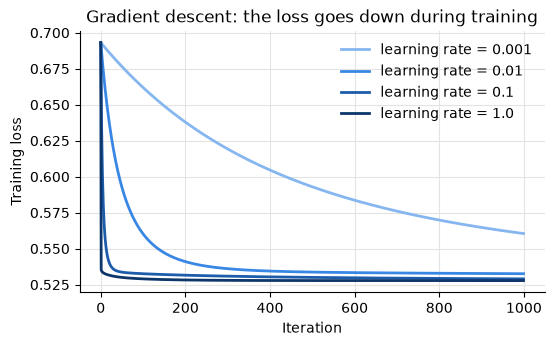

In [15]:
#trinas the model with each learning rate and saves the loss
loss_curves = {}
for rate in [0.001, 0.01, 0.1, 1.0]:
    model = LogisticRegression(learning_rate=rate, n_iterations=1000).fit(X_train_scaled, y_train)
    loss_curves[rate] = model.loss_history
    print(f"learning rate {rate:<6} final training loss = {model.loss_history[-1]:.4f}")

#pick learning rate with lowest final training loss
best_rate = min(loss_curves, key=lambda rate: loss_curves[rate][-1])
print(f"Best learning rate: {best_rate}")

#plot
fig, ax = plt.subplots(figsize=(6, 3.4))
for rate, color in zip(loss_curves, ["#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]):
    ax.plot(loss_curves[rate], color=color, linewidth=2, label=f"learning rate = {rate}")
ax.set_xlabel("Iteration")
ax.set_ylabel("Training loss")
ax.set_title("Gradient descent: the loss goes down during training")
ax.legend()
fig.savefig(FIG_DIR / "05_loss_curves.png")
plt.show()

### 7.2 Train the final model

In [16]:
log_reg = LogisticRegression(learning_rate=best_rate, n_iterations=1000).fit(X_train_scaled, y_train)
print(f"Final training loss: {log_reg.loss_history[-1]:.4f}")

Final training loss: 0.5278


## 8. Algorithm 2: Random Forest
A Random Forest trains many decision trees on random samples of the training data and lets them vote.
We choose `max_depth` (how deep each tree may grow) with **5-fold cross-validation** on the training set:
the training set is split into 5 parts, we train on 4 and test on the 5th, repeat 5 times and take the average.

In [17]:
#The different depths to try on the tree
depths = [1, 2, 3, 4, 6, 8, 10, 15, 20, None]
depth_train_acc, depth_cv_acc = [], []

for depth in depths:
    #200 trees trained on a random sample and only allowed to pick between 4 features so they make different mistakes. The forest gives the average
    forest = RandomForestClassifier(n_estimators=200, max_depth=depth, random_state=SEED, n_jobs=-1)
    cv_acc = cross_val_score(forest, X_train_scaled, y_train, cv=5).mean() # 5-fold CV

    #accuracy on the games it was trained on, compare with CV accuracy to check for overfitting, much higher than CV -> overfitting
    train_acc = forest.fit(X_train_scaled, y_train).score(X_train_scaled, y_train)
    depth_cv_acc.append(cv_acc)
    depth_train_acc.append(train_acc)
    print(f"max_depth={str(depth):<5} train accuracy = {train_acc:.4f}   CV accuracy = {cv_acc:.4f}")

best_depth = depths[int(np.argmax(depth_cv_acc))]
print(f"Best max_depth: {best_depth}")

max_depth=1     train accuracy = 0.7292   CV accuracy = 0.7263
max_depth=2     train accuracy = 0.7312   CV accuracy = 0.7273
max_depth=3     train accuracy = 0.7340   CV accuracy = 0.7285
max_depth=4     train accuracy = 0.7374   CV accuracy = 0.7286
max_depth=6     train accuracy = 0.7501   CV accuracy = 0.7290
max_depth=8     train accuracy = 0.7838   CV accuracy = 0.7277
max_depth=10    train accuracy = 0.8404   CV accuracy = 0.7278
max_depth=15    train accuracy = 0.9914   CV accuracy = 0.7235
max_depth=20    train accuracy = 1.0000   CV accuracy = 0.7240
max_depth=None  train accuracy = 1.0000   CV accuracy = 0.7242
Best max_depth: 6


Training accuracy keeps rising for deeper trees, but cross-validation accuracy does not, theyre overfitting


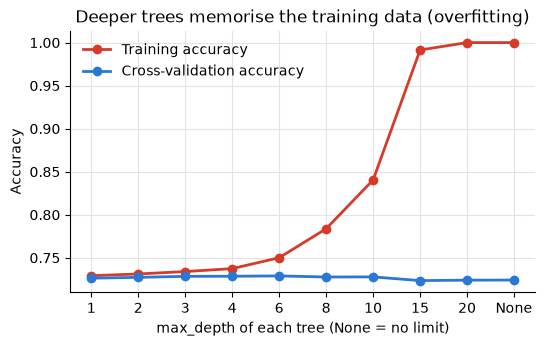

In [18]:
depth_labels = [str(d) for d in depths]
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.plot(depth_labels, depth_train_acc, color=RED, linewidth=2, marker="o", label="Training accuracy")
ax.plot(depth_labels, depth_cv_acc, color=BLUE, linewidth=2, marker="o", label="Cross-validation accuracy")
ax.set_xlabel("max_depth of each tree (None = no limit)")
ax.set_ylabel("Accuracy")
ax.set_title("Deeper trees memorise the training data (overfitting)")
ax.legend()
fig.savefig(FIG_DIR / "08_rf_depth_overfitting.png")
plt.show()

Train the final forest with the best depth and also one with no depth limit to compare

In [19]:
rf = RandomForestClassifier(n_estimators=200, max_depth=best_depth, random_state=SEED, n_jobs=-1)
rf.fit(X_train_scaled, y_train)

rf_default = RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1)  # no depth limit
rf_default.fit(X_train_scaled, y_train)
print("Both forests are trained")

Both forests are trained


## 9. Evaluate both models on the test set
- **Accuracy:** share of games predicted correctly
- **Precision:** when the model says "blue wins", how often is that true?
- **Recall:** of all games blue really won, how many did the model find?
- **F1-score:** one number that balances precision and recall

We also compare with two simple baselines: always guessing the most common class, and "the team with more gold wins".

In [20]:
def evaluate(model):
    y_pred = model.predict(X_test_scaled) #predictions
    return {
        #here to check for overfitting
        "train_accuracy": float(accuracy_score(y_train, model.predict(X_train_scaled))),
        "accuracy": float(accuracy_score(y_test, y_pred)),
        #these are calculated for blue won
        "precision": float(precision_score(y_test, y_pred)),
        "recall": float(recall_score(y_test, y_pred)),
        "f1": float(f1_score(y_test, y_pred)),
        #2x2
        "confusion_matrix": confusion_matrix(y_test, y_pred).tolist(),
    }


lr_metrics = evaluate(log_reg)
rf_metrics = evaluate(rf)
rf_default_metrics = evaluate(rf_default)

#Baseline: guess most common class which was blue lost
most_common_class = int(np.mean(y_train) >= 0.5)
majority_acc = float(accuracy_score(y_test, np.full(len(y_test), most_common_class)))

#Basline 2: team with most gold wins
gold_rule_acc = float(accuracy_score(y_test, (X_test["blueGoldDiff"] > 0).astype(int)))

## 10. Compare the results

In [21]:
print(f"Baseline 'always guess the most common class': {majority_acc:.4f}")
print(f"Baseline 'the team with more gold wins':       {gold_rule_acc:.4f}")

pd.DataFrame({
    "Logistic Regression": lr_metrics,
    "Random Forest (tuned)": rf_metrics,
    "Random Forest (no depth limit)": rf_default_metrics,
}).drop(index="confusion_matrix").astype(float).round(4)

Baseline 'always guess the most common class': 0.5010
Baseline 'the team with more gold wins':       0.7146


,Logistic Regression,Random Forest (tuned),Random Forest (no depth limit)
train_accuracy,0.7350,0.7501,1.0000
accuracy,0.7323,0.7287,0.7277
precision,0.7306,0.7310,0.7309
recall,0.7343,0.7221,0.7191
f1,0.7324,0.7265,0.7249


## 11. Visualisations of the models
### 11.1 Confusion matrices
Rows are the real result, columns are the prediction. The diagonal (top-left and bottom-right) hold the correct predictions

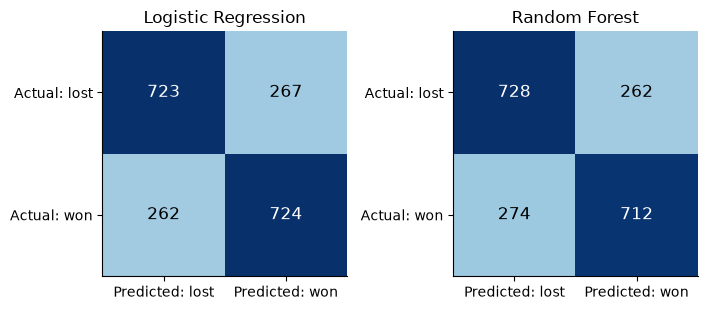

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(7.2, 3.2))
for ax, (name, metrics) in zip(axes, [("Logistic Regression", lr_metrics), ("Random Forest", rf_metrics)]):
    cm = np.array(metrics["confusion_matrix"])
    ax.imshow(cm, cmap="Blues", vmin=0)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=12,
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xticks([0, 1], ["Predicted: lost", "Predicted: won"])
    ax.set_yticks([0, 1], ["Actual: lost", "Actual: won"])
    ax.set_title(name)
    ax.grid(False)
fig.tight_layout()
fig.savefig(FIG_DIR / "06_confusion_matrices.png")
plt.show()

### 11.2 Which features mattered most
- Left: the Logistic Regression weights (positive helps blue win, negative helps red)
- Right: how much each feature helped the Random Forest splits

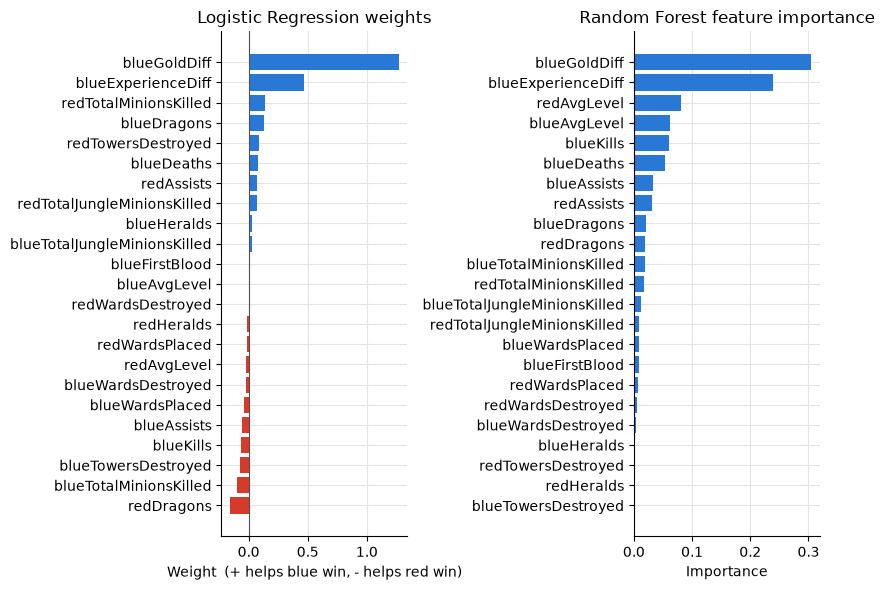

redDragons                     -0.1590
blueTotalMinionsKilled         -0.1025
blueTowersDestroyed            -0.0724
blueKills                      -0.0620
blueAssists                    -0.0546
blueWardsPlaced                -0.0419
blueWardsDestroyed             -0.0260
redAvgLevel                    -0.0198
redWardsPlaced                 -0.0138
redHeralds                     -0.0110
redWardsDestroyed               0.0008
blueAvgLevel                    0.0028
blueFirstBlood                  0.0041
blueTotalJungleMinionsKilled    0.0293
blueHeralds                     0.0305
redTotalJungleMinionsKilled     0.0668
redAssists                      0.0684
blueDeaths                      0.0776
redTowersDestroyed              0.0878
blueDragons                     0.1332
redTotalMinionsKilled           0.1358
blueExperienceDiff              0.4666
blueGoldDiff                    1.2721
dtype: float64
blueTowersDestroyed             0.0009
redHeralds                      0.0010
redTowersD

In [23]:
weights = pd.Series(log_reg.w, index=feature_names).sort_values()
importance = pd.Series(rf.feature_importances_, index=feature_names).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(8.4, 6))
axes[0].barh(weights.index, weights.values, color=[BLUE if v > 0 else RED for v in weights.values])
axes[0].axvline(0, color=GREY, linewidth=0.8)
axes[0].set_title("Logistic Regression weights")
axes[0].set_xlabel("Weight  (+ helps blue win, - helps red win)")
axes[1].barh(importance.index, importance.values, color=BLUE)
axes[1].set_title("Random Forest feature importance")
axes[1].set_xlabel("Importance")
fig.tight_layout()
fig.savefig(FIG_DIR / "07_feature_importance.png")
plt.show()
print(weights.round(4))
print(importance.round(4))